# 3 · When not to trade: a daily PCA gauge

**Idea:** each day, run PCA on the last 480 hourly returns (≈ 20 trading days) of the 11 instruments. The **share** of the first factor = largest eigenvalue ÷ 11 (eigenvalues of a correlation matrix add up to the number of series). High share = one force (mostly the dollar) drives everything; low share = currencies follow their own news.

**Tests**
1. Split days into thirds by the share (low / medium / high).
2. Every time a cross pair stretches (|s-score| crosses 2), check the next 10 days: did it **pull back** (|s| ≤ 0.5), **break** further (|s| ≥ 4 or model invalid), or neither?
3. Market shocks: where was the gauge?
4. Live rule using past data only: a day is *no-trade* when today's share ≤ the 33rd percentile of all previous days. Share of tradable days per year.
5. Real trades from `backtesting/04` split by whether they were opened on a no-trade day.

The s-score is (X − middle) / normal stretch from an Ornstein–Uhlenbeck fit on the pair's cumulative PCA leftover X.

In [1]:
from dataclasses import dataclass, replace
from dataclasses import replace
from itertools import product
from pathlib import Path
import argparse

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

%matplotlib inline
pd.set_option("display.width", 200)
ROOT = Path.cwd().parent   # repository root (run the notebook from its own folder); data lives in ROOT / "data"

### Forex PCA residual model

In [2]:
CCYS = ["EUR", "GBP", "AUD", "NZD", "CAD", "CHF", "JPY", "NOK", "SEK", "XAU", "XAG"]

CROSSES_8 = {  # symbol: (base, quote)
    "AUDNZD": ("AUD", "NZD"), "EURGBP": ("EUR", "GBP"), "EURCHF": ("EUR", "CHF"),
    "AUDCAD": ("AUD", "CAD"), "NZDCAD": ("NZD", "CAD"), "CADCHF": ("CAD", "CHF"),
    "EURNOK": ("EUR", "NOK"), "EURSEK": ("EUR", "SEK"),
}

# all 23 crosses downloaded (data_collection/01): the 8 above + the rest of the 28 pairs without USD
CROSSES_ALL = {**CROSSES_8, **{s: (s[:3], s[3:]) for s in [
    "EURJPY", "GBPJPY", "AUDJPY", "NZDJPY", "CADJPY", "CHFJPY", "EURAUD", "EURNZD",
    "EURCAD", "GBPAUD", "GBPNZD", "GBPCAD", "GBPCHF", "AUDCHF", "NZDCHF"]}}

# HistData has no spreads: assumed typical prop-firm raw spreads, as % of price (conservative)
SPREAD_PCT = {"AUDNZD": 0.018, "EURGBP": 0.012, "EURCHF": 0.016, "AUDCAD": 0.016,
              "NZDCAD": 0.024, "CADCHF": 0.025, "EURNOK": 0.035, "EURSEK": 0.036}

COMMISSION_PCT = 0.003  # per side, ~ $6 per 100k round turn
BARS_PER_YEAR = 5900  # hourly bars actually present per year in the data
CROSSES = CROSSES_8   # active universe; later cells may switch it to CROSSES_ALL
SWAP = "worst"        # daily / 4h tests: "worst" = charge the more expensive swap side, "none" = swap-free

In [3]:
@dataclass(frozen=True)
class Params:
    window: int = 480
    step: int = 24
    k: int = 3                 # PCA factors removed
    entry: float = 2.0
    exit: float = 0.5
    stop: float = 4.0
    max_hl: float = 48.0
    max_hold: int = 96
    target_vol: float = 0.05   # annual vol per open position
    max_lev: float = 30.0
    spread_mult: float = 1.0
    real_spreads: bool = False  # True: per-bar spreads recorded by Vantage MT5 (data/mt5_fx)
    bars_per_year: float = BARS_PER_YEAR  # 5900 for H1; set for other timeframes
    vol_lookback: int = 480     # bars used to size positions

In [4]:
def model_signals(r, pairs, prm):
    """Out-of-sample residuals and s-scores for each cross. r: (T, N) log returns of CCYS."""
    T = len(r)
    P = len(pairs)
    s = np.full((T, P), np.nan)
    hl = np.full((T, P), np.nan)
    resid = np.full((T, P), np.nan)
    explained = np.full(T, np.nan)
    for t0 in range(prm.window, T, prm.step):
        w = r[t0 - prm.window:t0]
        mu, sd = w.mean(0), w.std(0, ddof=1)
        z = (w - mu) / sd
        vals, vecs = np.linalg.eigh(np.corrcoef(z.T))
        o = vals.argsort()[::-1]
        V = vecs[:, o[:prm.k]]
        t1 = min(t0 + prm.step, T)
        explained[t0:t1] = vals[o[0]] / vals.sum()
        e_win = (z - z @ V @ V.T) * sd                         # residual returns, window
        zn = (r[t0:t1] - mu) / sd
        e_new = (zn - zn @ V @ V.T) * sd                       # residual returns, next bars (frozen model)
        for j, (a, b) in enumerate(pairs):
            p_win = e_win[:, a] - e_win[:, b]
            p_new = e_new[:, a] - e_new[:, b]
            resid[t0:t1, j] = p_new
            x = np.cumsum(p_win)
            bb, aa = np.polyfit(x[:-1], x[1:], 1)
            if not 0 < bb < 1:
                continue
            zeta = x[1:] - (aa + bb * x[:-1])
            m = aa / (1 - bb)
            sig = np.sqrt(zeta.var() / (1 - bb * bb))
            s[t0:t1, j] = (x[-1] + np.cumsum(p_new) - m) / sig
            hl[t0:t1, j] = np.log(2) / -np.log(bb)
    return s, hl, resid, explained

In [5]:
def backtest_one(px, s, hl, idx, cost_side, prm, carry=0.0):
    """One cross. px: closes, s/hl: signals at each bar close, cost_side: cost per side (scalar or per bar),
    carry: holding cost per bar while a position is open (swap), as a fraction of notional."""
    cost_side = np.broadcast_to(np.asarray(cost_side, dtype=float), (len(px),))
    carry = np.broadcast_to(np.asarray(carry, dtype=float), (len(px),))
    simple = np.r_[0.0, px[1:] / px[:-1] - 1]
    lr = np.r_[0.0, np.diff(np.log(px))]
    bar_target = prm.target_vol / np.sqrt(prm.bars_per_year)
    n = len(px)
    ret, gross = np.zeros(n), np.zeros(n)
    pos, lev, held, blocked, cur, trades = 0, 0.0, 0, 0, None, []
    for t in range(n):
        if pos != 0:
            g = pos * lev * simple[t]
            ret[t] += g - lev * carry[t]
            gross[t] += g
            cur["gross"] += g
            cur["cost"] += lev * carry[t]
            held += 1
        st = s[t]
        want, reason = pos, None
        if pos != 0:
            if np.isnan(st):
                want, reason = 0, "model invalid"
            elif (pos > 0 and st >= -prm.exit) or (pos < 0 and st <= prm.exit):
                want, reason = 0, "target"
            elif abs(st) >= prm.stop:
                want, reason = 0, "stop"
            elif held >= prm.max_hold:
                want, reason = 0, "time"
        if blocked and (np.isnan(st) or abs(st) < prm.entry):
            blocked = 0
        if want == 0 and pos == 0 and not blocked and not np.isnan(st) \
                and hl[t] <= prm.max_hl and prm.entry <= abs(st) < prm.stop:
            want = -1 if st > 0 else 1
        if want != pos:
            if pos != 0:
                ret[t] -= lev * cost_side[t]
                cur.update(cost=cur["cost"] + lev * cost_side[t], exit=idx[t], bars=held, reason=reason)
                trades.append(cur)
                blocked = 1 if reason in ("stop", "time") else 0
            if want != 0:
                vol = lr[max(0, t - prm.vol_lookback):t + 1].std()
                lev = min(bar_target / vol, prm.max_lev) if vol > 0 else 0.0
                ret[t] -= lev * cost_side[t]
                cur = {"entry": idx[t], "dir": want, "s_entry": st, "half_life": hl[t], "lev": lev,
                       "gross": 0.0, "cost": lev * cost_side[t]}
                held = 0
            pos = want
    tr = pd.DataFrame(trades)
    if len(tr):
        tr["net"] = tr["gross"] - tr["cost"]
    return ret, gross, tr

In [6]:
def variance_ratio(x, k):
    x = pd.Series(x).dropna()
    agg = x.rolling(k).sum().iloc[k - 1::k]
    return agg.var() / (k * x.var())

### Daily / 4-hour candles, costs and walk-forward engine

In [7]:
SPLIT = pd.Timestamp("2019-01-01", tz="UTC")

TF = {
    # bars per trading day, bars per year, model re-fit step, grid
    "D1": {"per_day": 1, "per_year": 260, "step": 5,
           "grid": {"window": [60, 120, 250], "entry": [1.5, 2.0, 2.5], "exit": [0.0, 0.5], "max_hl": [5, 10, 20]}},
    "H4": {"per_day": 6, "per_year": 1560, "step": 6,
           "grid": {"window": [180, 360, 720], "entry": [1.5, 2.0, 2.5], "exit": [0.0, 0.5], "max_hl": [12, 30, 60]}},
}

In [8]:
def candle_key(idx, tf):
    """Group hourly UTC timestamps into candles that start at 17:00 New York (MT5 broker convention)."""
    shifted = idx.tz_convert("America/New_York").tz_localize(None) + pd.Timedelta(hours=7)
    return shifted.floor("D" if tf == "D1" else "4h")

In [9]:
def to_candles(hourly, tf, how="last"):
    key = candle_key(hourly.index, tf)
    g = hourly.groupby(key)
    out = g.last() if how == "last" else g.median()
    stamps = hourly.index.to_series().groupby(key).last()  # stamp = last hour in the candle (UTC)
    out.index = pd.DatetimeIndex(stamps.reindex(out.index).to_list(), name="time_utc")
    return out

In [10]:
def load(tf):
    d = ROOT / "data/histdata_fx"
    cur_h = pd.read_csv(d / "currencies_1h.csv", index_col=0, parse_dates=True)[CCYS]
    crs_h = pd.read_csv(d / "crosses_1h.csv", index_col=0, parse_dates=True)[list(CROSSES)]
    for sym, (a, b) in CROSSES.items():  # gaps in a cross's own file -> rebuild from the majors
        crs_h[sym] = crs_h[sym].fillna(cur_h[a] / cur_h[b])
    cur = to_candles(cur_h.ffill(limit=3), tf).dropna()
    crs = to_candles(crs_h.ffill(limit=3), tf).reindex(cur.index).ffill()

    # spreads: Vantage hourly spreads -> median per candle; earlier years -> each cross's overall median
    sp_h = pd.read_csv(ROOT / "data/mt5_fx/crosses_1h.csv", index_col=0, parse_dates=True)
    sp_h = sp_h[[f"{s}_spread" for s in CROSSES]]
    sp_h.columns = list(CROSSES)
    sp = to_candles(sp_h, tf, how="median").reindex(cur.index)
    sp = sp.fillna(sp_h.median())

    swaps = pd.read_csv(ROOT / "data/mt5_fx/swaps.csv", index_col=0)
    worst = (-swaps[["long %/night", "short %/night"]].astype(float)).max(axis=1).clip(lower=0) / 100
    per_bar_swap = worst.reindex(list(CROSSES)) * 7 / 5 / TF[tf]["per_day"] * (SWAP == "worst")  # 7 nights paid over 5 trading days
    return cur, crs, sp, per_bar_swap

In [11]:
def run_tf(cur, crs, sp, swap, prm, sig=None):
    r = np.log(cur[CCYS]).diff().to_numpy()[1:]
    idx = cur.index[1:]
    pairs = [(CCYS.index(a), CCYS.index(b)) for a, b in CROSSES.values()]
    if sig is None:
        sig = model_signals(r, pairs, prm)
    s, hl, *_ = sig
    per = {}
    for j, sym in enumerate(CROSSES):
        cost = sp[sym].reindex(idx).to_numpy() / 2 * prm.spread_mult + COMMISSION_PCT / 100
        ret, gross, tr = backtest_one(crs[sym].reindex(idx).to_numpy(), s[:, j], hl[:, j], idx, cost, prm,
                                      carry=swap[sym])
        per[sym] = (ret, gross, tr)
    return per, sig, idx

In [12]:
def perf(ret, per_year):
    ret = pd.Series(ret)
    if len(ret) == 0 or ret.std() == 0:
        return {"Sharpe": np.nan, "%/yr": 0.0, "maxDD %": 0.0}
    eq = (1 + ret).cumprod()
    return {"Sharpe": ret.mean() / ret.std() * np.sqrt(per_year), "%/yr": ret.mean() * per_year * 100,
            "maxDD %": (eq / eq.cummax() - 1).min() * 100}

In [13]:
def combine(per, syms, idx, mask, k=0):
    arr = sum(per[s][k] for s in syms) if syms else np.zeros(len(idx))
    return pd.Series(arr[mask], index=idx[mask])

In [14]:
def trades(per, syms, lo, hi):
    t = [per[s][2].assign(symbol=s) for s in syms if len(per[s][2])]
    t = pd.concat(t, ignore_index=True) if t else pd.DataFrame(columns=["entry", "net", "gross", "cost", "bars"])
    return t[(t["entry"] >= lo) & (t["entry"] < hi)]

### Gold/silver PCA model

In [15]:
ASSETS = ["xau", "xag", "usdx"]

LOT_OZ = {"xau": 100, "xag": 5000}  # standard MT5 lot sizes

BARS_PER_YEAR = 5900  # hourly bars actually present per year in the data

In [16]:
@dataclass(frozen=True)
class GSParams:
    window: int = 480          # bars used to fit PCA + OU (~4 weeks)
    step: int = 24             # re-fit every N bars
    entry: float = 2.0         # |s| to open
    exit: float = 0.5          # |s| to close at equilibrium
    stop: float = 4.0          # |s| stop-loss (model broken)
    max_hl: float = 48.0       # only trade if OU half-life <= this many bars
    max_hold: int = 96         # time stop, bars
    target_vol: float = 0.10   # annual volatility target while in a trade
    max_lev: float = 10.0      # cap on gross notional / equity
    spread_mult: float = 1.5   # demo spreads are optimistic; prop spreads are wider
    commission: float = 6.0    # $ per lot round turn (typical prop firm)
    flat_weekend: bool = False  # close before the Friday close

In [17]:
def fit(r_win):
    """PCA + OU on one window of returns. Returns dict or None if not mean-reverting."""
    mu, sd = r_win.mean(0), r_win.std(0, ddof=1)
    z = (r_win - mu) / sd
    vals, vecs = np.linalg.eigh(np.corrcoef(z.T))
    v3 = vecs[:, vals.argsort()[0]]           # smallest-variance component = PC3
    v3 = v3 * np.sign(v3[1])                  # orient: long silver
    w = v3[:2] / sd[:2]                       # dollar weights, gold & silver legs only
    w = w / np.abs(w).sum()                   # $1 gross
    spread = r_win[:, :2] @ w
    x = np.cumsum(spread)
    b, a = np.polyfit(x[:-1], x[1:], 1)
    if not 0 < b < 1:
        return None
    zeta = x[1:] - (a + b * x[:-1])
    return {
        "w": w, "x_last": x[-1], "m": a / (1 - b),
        "sigma_eq": np.sqrt(zeta.var() / (1 - b * b)),
        "hl": np.log(2) / -np.log(b),
        "lev": None if spread.std() == 0 else spread.std(),
        "usdx_loading": v3[2],
    }

In [18]:
def signals(r, prm):
    """s-score, half-life, weights and spread vol for every bar (using only past data)."""
    n = len(r)
    s = np.full(n, np.nan)
    hl = np.full(n, np.nan)
    W = np.full((n, 2), np.nan)
    vol = np.full(n, np.nan)
    for t0 in range(prm.window, n, prm.step):
        f = fit(r[t0 - prm.window:t0])
        if f is None:
            continue
        t1 = min(t0 + prm.step, n)
        # extend the cumulative spread with new bars, model frozen until next re-fit
        x = f["x_last"] + np.cumsum(r[t0:t1, :2] @ f["w"])
        s[t0:t1] = (x - f["m"]) / f["sigma_eq"]
        hl[t0:t1] = f["hl"]
        W[t0:t1] = f["w"]
        vol[t0:t1] = f["lev"]
    return s, hl, W, vol

In [19]:
def backtest(panel, prm):
    px = panel[["xau", "xag"]].to_numpy()
    r = np.log(panel[ASSETS]).diff().to_numpy()[1:]
    idx = panel.index[1:]
    simple = px[1:] / px[:-1] - 1
    half_spread = 0.5 * prm.spread_mult * (panel[["xau_spread", "xag_spread"]].to_numpy()[1:] / px[1:])
    comm = np.column_stack([(prm.commission / 2) / (LOT_OZ[a] * px[1:, i]) for i, a in enumerate(["xau", "xag"])])
    s, hl, W, vol = signals(r, prm)

    hourly_target = prm.target_vol / np.sqrt(BARS_PER_YEAR)
    weekday, hour = idx.weekday, idx.hour
    n = len(r)
    ret = np.zeros(n)          # strategy return per bar (net of costs)
    gross = np.zeros(n)
    pos, w_e, lev_e, held, blocked = 0, None, 0.0, 0, 0
    trades, cur = [], None

    for t in range(n):
        # 1) P&L of the position held over bar t
        if pos != 0:
            g = pos * lev_e * (w_e @ simple[t])
            ret[t] += g
            gross[t] += g
            cur["gross"] += g
            held += 1

        # 2) decide at the close of bar t
        st = s[t]
        want = pos
        reason = None
        friday_close = prm.flat_weekend and weekday[t] == 4 and hour[t] >= 19
        if pos != 0:
            if np.isnan(st):
                want, reason = 0, "model invalid"
            elif (pos > 0 and st >= -prm.exit) or (pos < 0 and st <= prm.exit):
                want, reason = 0, "target"
            elif abs(st) >= prm.stop:
                want, reason = 0, "stop"
            elif held >= prm.max_hold:
                want, reason = 0, "time"
            elif friday_close:
                want, reason = 0, "weekend"
        if blocked and (np.isnan(st) or abs(st) < prm.entry):
            blocked = 0
        if want == 0 and pos == 0 and not blocked and not friday_close and not np.isnan(st) \
                and hl[t] <= prm.max_hl and prm.entry <= abs(st) < prm.stop:
            want = -1 if st > 0 else 1   # s high -> silver rich vs gold -> sell spread

        # 3) trade + costs
        if want != pos:
            if pos != 0:  # close
                c = lev_e * np.abs(w_e) @ (half_spread[t] + comm[t])
                ret[t] -= c
                cur.update(cost=cur["cost"] + c, exit=idx[t], bars=held, reason=reason, s_exit=st)
                trades.append(cur)
                if reason in ("stop", "time"):
                    blocked = 1
            if want != 0:  # open
                w_e = W[t]
                lev_e = min(hourly_target / vol[t], prm.max_lev) if vol[t] > 0 else 0.0
                c = lev_e * np.abs(w_e) @ (half_spread[t] + comm[t])
                ret[t] -= c
                cur = {"entry": idx[t], "dir": "long spread" if want > 0 else "short spread",
                       "s_entry": st, "half_life": hl[t], "lev": lev_e,
                       "w_gold": w_e[0], "w_silver": w_e[1], "gross": 0.0, "cost": c}
                held = 0
            pos = want

    eq = pd.DataFrame({"ret": ret, "gross": gross, "s": s, "in_trade": 0}, index=idx)
    tr = pd.DataFrame(trades)
    if len(tr):
        tr["net"] = tr["gross"] - tr["cost"]
    return eq, tr

In [20]:
def load_panel():
    return pd.read_csv(ROOT / "data/mt5/panel_1h.csv", index_col=0, parse_dates=True)

def residual_returns(panel, prm=GSParams()):
    """Out-of-sample returns of the silver-vs-gold (PC3) portfolio, model re-fit on past data only."""
    r = np.log(panel[ASSETS]).diff().to_numpy()[1:]
    s, hl, W, vol = signals(r, prm)
    return pd.Series((r[:, :2] * W).sum(1), index=panel.index[1:]).where(~np.isnan(W[:, 0])).dropna()

def gs_trades(panel=None):
    """Trades of the gold/silver residual strategy with its default settings."""
    eq, tr = backtest(load_panel() if panel is None else panel, GSParams())
    return eq, tr

### The chosen daily setup (from the walk-forward) and its trades

In [21]:
# chosen on 2010-2018 only by: backtesting/04, section 3
CHOSEN = dict(window=120, entry=2.5, exit=0.5, max_hl=10)

KEPT = ["AUDNZD", "EURGBP", "AUDCAD", "NZDCAD", "EURNOK", "EURSEK", "EURJPY", "GBPJPY", "AUDJPY",
        "EURAUD", "EURNZD", "GBPCAD", "NZDCHF"]

In [22]:
def load_d1():
    global CROSSES, SWAP
    CROSSES = CROSSES_ALL
    SWAP = "none"
    return load("D1")

In [23]:
def fx_trades(data=None):
    """Trades and daily returns of the chosen D1 setup on the kept crosses (swap-free)."""
    cur, crs, sp, sw = load_d1() if data is None else data
    cfg = TF["D1"]
    prm = replace(Params(), step=cfg["step"], max_hold=int(3 * CHOSEN["max_hl"]), bars_per_year=cfg["per_year"],
                  vol_lookback=CHOSEN["window"], **CHOSEN)
    per, sig, idx = run_tf(cur, crs, sp, sw, prm)
    tr = pd.concat([per[s][2].assign(symbol=s) for s in KEPT if len(per[s][2])], ignore_index=True)
    return tr, pd.Series(sum(per[s][0] for s in KEPT), index=idx)

### Concentration gauge settings

In [24]:
OUT = ROOT / "data" / "regime"

WIN_H = 480          # hourly bars in the concentration window (~20 trading days)

FWD = 10             # days to wait for a stretched pair to snap back

EVENTS = {
    "2010-05-06": "Euro crisis / flash crash", "2011-08-08": "US downgrade",
    "2015-01-15": "SNB drops CHF floor", "2016-06-24": "Brexit vote",
    "2020-03-16": "COVID crash", "2022-09-26": "UK gilt crisis", "2025-04-03": "US tariff shock",
}

In [25]:
def pc1_share(z):
    vals = np.linalg.eigvalsh(np.corrcoef(z.T))
    return vals[-1] / vals.sum()

## Analysis

In [26]:
OUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200)

In [27]:
# ---- daily candles + out-of-sample pair model (same settings as the D1 study)
CROSSES = CROSSES_ALL
cur, crs, *_ = load("D1")
r = np.log(cur[CCYS]).diff().to_numpy()[1:]
idx = cur.index[1:]
names = list(CROSSES)
pairs = [(CCYS.index(a), CCYS.index(b)) for a, b in CROSSES.values()]
prm = replace(Params(), window=120, step=5, k=3)
s, hl, resid, _ = model_signals(r, pairs, prm)

In [28]:
# ---- concentration from hourly returns, known at each daily close
h = pd.read_csv(ROOT / "data/histdata_fx/currencies_1h.csv", index_col=0, parse_dates=True)[CCYS]
hr = np.log(h.ffill(limit=3)).diff().dropna()
pos = hr.index.searchsorted(idx, side="right")       # hourly bars up to and including the daily close
share = np.full(len(idx), np.nan)
share9 = np.full(len(idx), np.nan)
hv = hr.to_numpy()
for i, p in enumerate(pos):
    if p >= WIN_H:
        w = hv[p - WIN_H:p]
        share[i] = pc1_share(w)
        share9[i] = pc1_share(w[:, :9])
conc = pd.Series(share, index=idx, name="pc1_share")
q1, q2 = conc.quantile([1 / 3, 2 / 3])
regime = pd.Series(np.where(conc <= q1, "low", np.where(conc <= q2, "medium", "high")), index=idx)
regime[conc.isna()] = None
print(f"First-factor share (20-day hourly PCA): median {conc.median():.0%}, "
      f"low <= {q1:.0%} < medium <= {q2:.0%} < high, max {conc.max():.0%}")
print(f"corr with FX-only (9 currencies, no metals) version: {np.corrcoef(share[~np.isnan(share)], share9[~np.isnan(share)])[0, 1]:.2f}")

First-factor share (20-day hourly PCA): median 52%, low <= 48% < medium <= 57% < high, max 76%
corr with FX-only (9 currencies, no metals) version: 0.97


In [29]:
# ---- stretched pairs: snap back or break?
ev = []
T_, P = s.shape
for j in range(P):
    for t in range(1, T_ - FWD):
        if regime.iloc[t] is None or np.isnan(s[t, j]) or abs(s[t, j]) < 2 or \
                (not np.isnan(s[t - 1, j]) and abs(s[t - 1, j]) >= 2):
            continue
        out = "neither"
        for f in range(t + 1, t + FWD + 1):
            x = s[f, j]
            if np.isnan(x) or abs(x) >= 4:
                out = "broke"
                break
            if abs(x) <= 0.5:
                out = "snapped back"
                break
        ev.append({"date": idx[t], "pair": names[j], "s": s[t, j], "regime": regime.iloc[t], "outcome": out})
ev = pd.DataFrame(ev)
ev.to_csv(OUT / "stretch_events.csv", index=False)

order = ["low", "medium", "high"]
tab = pd.crosstab(ev["regime"], ev["outcome"], normalize="index").reindex(order) * 100
tab["events"] = ev["regime"].value_counts().reindex(order)

In [30]:
# ---- model health + forward volatility per regime
valid = pd.Series((~np.isnan(s)).mean(1), index=idx)
med_hl = pd.Series(np.nanmedian(np.where(np.isnan(s), np.nan, hl), axis=1), index=idx)
lr = np.log(crs[names].reindex(idx)).diff()
fwd_vol = lr.abs().mean(1).rolling(20).mean().shift(-20) * np.sqrt(260) * np.sqrt(np.pi / 2) * 100
health = pd.DataFrame({"pairs with mean reversion %": valid * 100, "median half-life (days)": med_hl,
                       "next-20d cross vol %/yr": fwd_vol, "regime": regime}).groupby("regime").mean().reindex(order)

res = pd.concat([tab[["snapped back", "broke", "neither", "events"]], health], axis=1)
res.to_csv(OUT / "regime_summary.csv")
print(f"\nStretched pairs (|s| crosses 2) — what happens in the next {FWD} days, by regime on that day:")
print(res.round(1).to_string())

# by year: is it consistent?
ev["year"] = ev["date"].dt.year
yr = ev.assign(snap=ev["outcome"] == "snapped back").pivot_table(index="year", columns="regime",
                                                                 values="snap", aggfunc="mean")[order] * 100
yr.to_csv(OUT / "snapback_by_year.csv")
print("\nsnap-back % by year and regime:")
print(yr.round(0).to_string())


Stretched pairs (|s| crosses 2) — what happens in the next 10 days, by regime on that day:
        snapped back  broke  neither  events  pairs with mean reversion %  median half-life (days)  next-20d cross vol %/yr
regime                                                                                                                     
low             41.5    7.7     50.8    1295                        100.0                     10.5                      8.7
medium          38.9    6.0     55.1    1100                         97.0                     11.5                      8.5
high            44.8    2.3     52.8     950                         96.2                     10.3                      7.6

snap-back % by year and regime:
regime   low  medium   high
year                       
2010    33.0    41.0   57.0
2011    46.0    47.0   19.0
2012    38.0    27.0   24.0
2013    41.0    32.0  100.0
2014    34.0    48.0   41.0
2015    34.0    26.0   31.0
2016    39.0    32.0   43.0
201

C:\Users\Admin\AppData\Local\Temp\ipykernel_12332\1299665046.py:3: RuntimeWarning: All-NaN slice encountered
  med_hl = pd.Series(np.nanmedian(np.where(np.isnan(s), np.nan, hl), axis=1), index=idx)


In [31]:
# ---- shocks
print("\nKnown shocks: highest first-factor share in the 20 days after, and its percentile in 2010-2026:")
rows = []
for d, name in EVENTS.items():
    w = conc[(conc.index >= pd.Timestamp(d, tz="UTC")) & (conc.index < pd.Timestamp(d, tz="UTC") + pd.Timedelta(days=28))]
    if len(w) and w.notna().any():
        pk = w.max()
        rows.append({"date": d, "event": name, "peak share %": pk * 100,
                     "percentile": (conc < pk).mean() * 100, "regime at peak": regime[w.idxmax()]})
shocks = pd.DataFrame(rows)
shocks.to_csv(OUT / "shocks.csv", index=False)
print(shocks.round(0).to_string(index=False))

pd.DataFrame({"pc1_share": conc, "pc1_share_fx_only": share9, "regime": regime}).to_csv(OUT / "concentration_daily.csv")


Known shocks: highest first-factor share in the 20 days after, and its percentile in 2010-2026:
      date                     event  peak share %  percentile regime at peak
2010-05-06 Euro crisis / flash crash          58.0        72.0           high
2011-08-08              US downgrade          45.0        25.0            low
2015-01-15       SNB drops CHF floor          40.0        13.0            low
2016-06-24               Brexit vote          57.0        68.0           high
2020-03-16               COVID crash          46.0        29.0            low
2022-09-26            UK gilt crisis          72.0        99.0           high
2025-04-03           US tariff shock          48.0        36.0         medium


In [32]:
# ---- 5. live-style no-trade rule: cut-off from past days only (needs 1 year of history)
cut = conc.expanding(min_periods=260).quantile(1 / 3).shift(1)
live = (conc > cut).where(cut.notna() & conc.notna()).dropna().astype(bool)
tradable = live.groupby(live.index.year).agg(days="size", tradable_pct=lambda x: x.mean() * 100)
tradable["avg share %"] = conc.groupby(conc.index.year).mean() * 100
low = ~live
runs = low.groupby((low != low.shift()).cumsum()).agg(["first", "size"])
spells = runs[runs["first"]]["size"]
print(f"\nLive no-trade rule (bottom third of past days): tradable {live.mean() * 100:.0f}% of days overall")
print(tradable.round(0).to_string())
print(f"no-trade spells: {len(spells)}, median {spells.median():.0f} days, longest {spells.max()} days")
tradable.to_csv(OUT / "tradable_days_by_year.csv")


Live no-trade rule (bottom third of past days): tradable 69% of days overall
          days  tradable_pct  avg share %
time_utc                                 
2010        11         100.0         54.0
2011       273          51.0         50.0
2012       263          79.0         55.0
2013       262          33.0         45.0
2014       263          31.0         42.0
2015       264          54.0         48.0
2016       262          63.0         47.0
2017       262          70.0         50.0
2018       262          82.0         52.0
2019       259          47.0         43.0
2020       260          74.0         50.0
2021       260          97.0         56.0
2022       260          93.0         60.0
2023       260          62.0         54.0
2024       260          93.0         58.0
2025       259          87.0         55.0
2026       206         100.0         61.0
no-trade spells: 44, median 10 days, longest 236 days


In [33]:
# ---- 6. trades opened on no-trade vs trade days
flag = pd.Series(np.where(live, "trade", "no-trade"), index=live.index)
rows = []
for name, tr in [("forex D1, 13 crosses", fx_trades()[0]), ("gold/silver H1", gs_trades()[1])]:
    tr = tr.assign(day=flag.reindex(tr["entry"], method="ffill").to_numpy()).dropna(subset=["day"])
    for (per, day), g in tr.groupby([np.where(tr["entry"] < SPLIT, "2010-18", "2019-26"), "day"]):
        rows.append({"strategy": name, "period": per, "opened on": day, "trades": len(g),
                     "win %": (g["net"] > 0).mean() * 100, "stopped out %": (g["reason"] == "stop").mean() * 100,
                     "avg net per trade %": g["net"].mean() * 100})
    rows += [{"strategy": name, "period": "all", "opened on": day, "trades": len(g),
              "win %": (g["net"] > 0).mean() * 100, "stopped out %": (g["reason"] == "stop").mean() * 100,
              "avg net per trade %": g["net"].mean() * 100} for day, g in tr.groupby("day")]
bt = pd.DataFrame(rows).set_index(["strategy", "period", "opened on"]).sort_index()
print("\nTrades by the day they were opened (costs included):")
print(bt.round(2).to_string())
bt.to_csv(OUT / "trades_by_regime.csv")


Trades by the day they were opened (costs included):
                                        trades  win %  stopped out %  avg net per trade %
strategy             period  opened on                                                   
forex D1, 13 crosses 2010-18 no-trade      122  68.85          12.30                 0.38
                             trade         111  63.06           7.21                 0.22
                     2019-26 no-trade       64  59.38          15.62                 0.04
                             trade         175  68.57           8.57                 0.17
                     all     no-trade      186  65.59          13.44                 0.26
                             trade         286  66.43           8.04                 0.19
gold/silver H1       2019-26 no-trade       12  41.67          16.67                -0.20
                             trade          92  54.35          19.57                -0.16
                     all     no-trade       12


charts in G:\pca-forex-analysis\data\regime


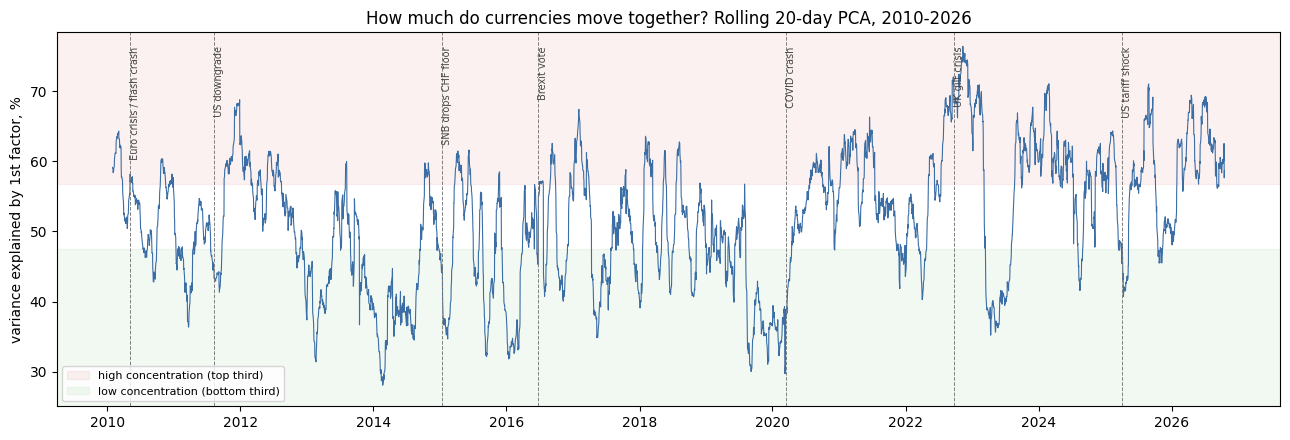

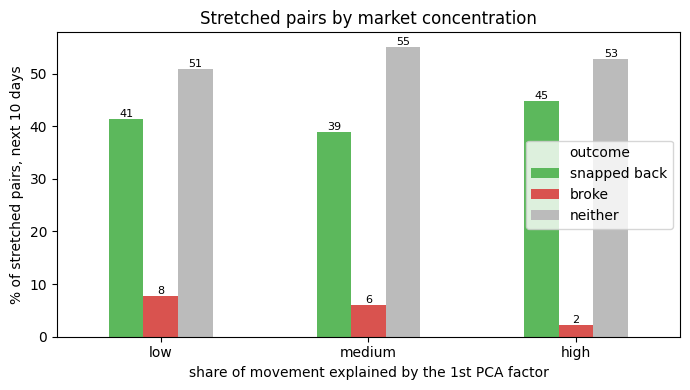

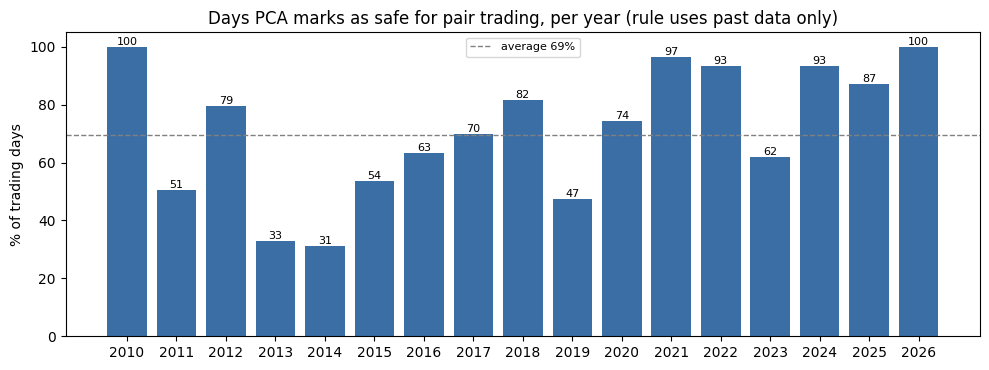

In [34]:
# ---- charts
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(conc.index, conc * 100, lw=0.8, color="#3b6ea5")
ax.axhspan(q2 * 100, 100, color="#d9534f", alpha=0.08, label="high concentration (top third)")
ax.axhspan(0, q1 * 100, color="#5cb85c", alpha=0.08, label="low concentration (bottom third)")
for d, name in EVENTS.items():
    ax.axvline(pd.Timestamp(d, tz="UTC"), color="grey", lw=0.7, ls="--")
    ax.text(pd.Timestamp(d, tz="UTC"), conc.max() * 100, " " + name, rotation=90, va="top", fontsize=7, color="#444")
ax.set_ylim(conc.min() * 100 - 3, conc.max() * 100 + 2)
ax.set_ylabel("variance explained by 1st factor, %")
ax.set_title("How much do currencies move together? Rolling 20-day PCA, 2010-2026")
ax.legend(loc="lower left", fontsize=8)
fig.tight_layout()
fig.savefig(OUT / "concentration.png", dpi=150)

fig, ax = plt.subplots(figsize=(7, 4))
tab[["snapped back", "broke", "neither"]].plot.bar(ax=ax, color=["#5cb85c", "#d9534f", "#bbbbbb"], rot=0)
ax.set_ylabel(f"% of stretched pairs, next {FWD} days")
ax.set_title("Stretched pairs by market concentration")
ax.set_xlabel("share of movement explained by the 1st PCA factor")
for c in ax.containers:
    ax.bar_label(c, fmt="%.0f", fontsize=8)
fig.tight_layout()
fig.savefig(OUT / "snapback_by_regime.png", dpi=150)

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(tradable.index.astype(str), tradable["tradable_pct"], color="#3b6ea5")
ax.axhline(live.mean() * 100, color="grey", ls="--", lw=1, label=f"average {live.mean() * 100:.0f}%")
ax.set_ylim(0, 105); ax.set_ylabel("% of trading days")
ax.set_title("Days PCA marks as safe for pair trading, per year (rule uses past data only)")
for c in ax.containers:
    ax.bar_label(c, fmt="%.0f", fontsize=8)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUT / "tradable_days_by_year.png", dpi=150)
print(f"\ncharts in {OUT}")

### What this shows
* Stretched pairs **break about 3× more often when the gauge is low (7.7% vs 2.3%)**, in every period 2010 – 2026 and in **22 of 23 pairs** (exception: AUDNZD).
* Shocks that split currencies into safe vs risky (COVID 2020, SNB 2015, US downgrade 2011) push the share **down**.
* The live rule marks **≈ 69% of days tradable** on average: 31 – 33% in 2013 – 14, 87 – 100% in 2021 – 26; no-trade spells typically last ≈ 10 days.
* Real trades opened on no-trade days hit their stop **13.4% vs 8.0%** of the time. In 2010 – 18 they still earned more per trade, so the gauge is a **risk warning, not a profit rule**.

**Conclusion:** PCA tells us when not to trust relationships between currency pairs.